In [1]:
import pysam
import sgkit as sg
from sgkit.io.vcf import vcf_to_zarr

vcf_gz = "03.pruned.vcf.gz"

# Step 1: Compress the VCF using bgzip (if not already compressed)
# pysam.tabix_compress(vcf_file, vcf_gz, force=True)

# Step 2: Index the bgzipped VCF file
pysam.tabix_index(vcf_gz, preset="vcf", force=True)

vcf_to_zarr(vcf_gz, "./ticks.zarr")

/home/jkliang/drem/dreems/.venv/lib/python3.11/site-packages/sgkit/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution  # type: ignore[import]


In [1]:
import xarray as xr
import numpy as np
import pandas as pd

# Read a local Zarr store
ds = xr.open_zarr("./ticks.zarr")

# coord = np.loadtxt("coord_03.txt")  # sample coordinates
outer = np.loadtxt("polygon_outer.txt")

df = pd.read_excel("Metadata.xlsx")

# Create the dictionary
id_to_region = dict(zip(df["id"], df["region"]))

prefixes_to_update = ("BARA", "JWWE", "FAYE")

pop_map = {
    sample_id: (
        "UP-MI" if sample_id.startswith(prefixes_to_update)
        else "LP-MI"
    ) if region == "MI" else region
    for sample_id, region in id_to_region.items()
}

sample_coordinates = {
    row["id"]: (row["long"], row["lat"])
    for _, row in df.iterrows()
}

Number of nodes: 3513
Number of edges: 10288


<Figure size 5000x4000 with 0 Axes>

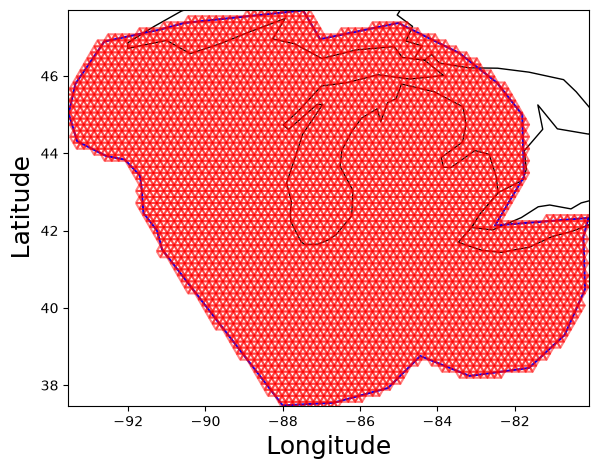

In [2]:
from dreems.utils.utility import create_grid
import networkx as nx

G = create_grid(outer, grid_size=0.18, pad = 0.01)
nodes = np.array([list(coord) for coord in nx.get_node_attributes(G, 'pos').values()])
edges = np.array(list(G.edges))

Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda12.initialize()
Traceback (most recent call last):
  File "/home/jkliang/drem/dreems/.venv/lib/python3.11/site-packages/jax/_src/xla_bridge.py", line 508, in discover_pjrt_plugins
    plugin_module.initialize()
  File "/home/jkliang/drem/dreems/.venv/lib/python3.11/site-packages/jax_plugins/xla_cuda12/__init__.py", line 370, in initialize
    _check_cuda_versions(raise_on_first_error = True)
  File "/home/jkliang/drem/dreems/.venv/lib/python3.11/site-packages/jax_plugins/xla_cuda12/__init__.py", line 274, in _check_cuda_versions
    for d in range(cuda_versions.cuda_device_count())
                   ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: jaxlib/cuda/versions_helpers.cc:135: operation cuInit(0) failed: Unknown CUDA error 303; cuGetErrorName failed. This probably means that JAX was unable to load the CUDA libraries.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed.

{"conditioner_failure_examples": [], "conditioner_failures": 0, "conditioner_observed_nodes_mean": 42.0, "conditioner_observed_pairs_mean": 861.0, "conditioner_seconds_total": 0.33973952382802963, "edge_conditioner": "linearized_resistance", "edge_conditioner_methods": ["all_pair_diagonal_adjoint"], "edge_dim_after": 253, "edge_dim_before": 251, "examples": 1, "stage": "append_edge_conditioner_features"}


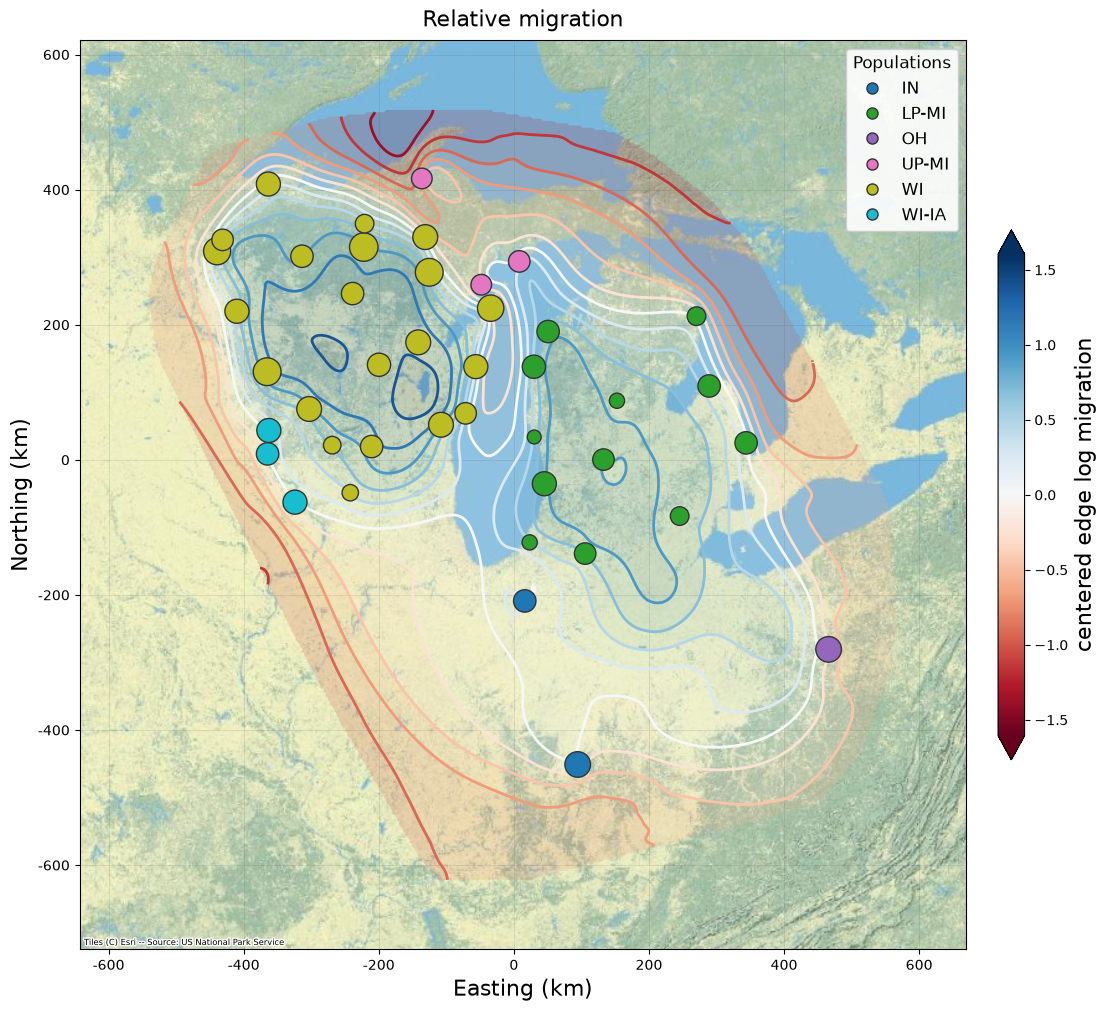

(<Figure size 1200x1000 with 2 Axes>,
 <Axes: title={'center': 'Relative migration'}, xlabel='Easting (km)', ylabel='Northing (km)'>)

In [3]:
from dreems.utils.utility import dreems_infer

surface = dreems_infer(ds, sample_coordinates, nodes, edges)

from dreems.utils.plotting import draw_projected_contour_map
draw_projected_contour_map(
    surface,
    sample_to_pop=pop_map,
    smoothing_km=5.0,
    contour_levels=15,
    contour_linewidth=2.0,
    contour_fill_alpha=0.20,
)

## Retrieving FEEMS genotype matrix that's been MAF and call rate filtered, and missing data imputed

In [4]:
def _standardized_genotypes(
    calls: xr.DataArray,
    *,
    min_maf: float,
    min_variant_call_rate: float,
) -> tuple[xr.DataArray, int]:
    """Filter calls, impute variant means, and scale dosages to sample variance one.

    Reductions stay in xarray, so a chunked input does not require loading the
    full genotype tensor. Small QC summaries are computed before indexing.
    """
    sample_called = (calls >= 0).all(dim="ploidy")
    dosage = calls.where(sample_called).sum(dim="ploidy", skipna=True).where(sample_called)
    called_count = sample_called.sum(dim="samples")
    call_rate = called_count / float(calls.sizes["samples"])
    allele_frequency = dosage.sum(dim="samples", skipna=True) / (
        float(calls.sizes["ploidy"]) * called_count
    )
    maf = xr.where(allele_frequency <= 0.5, allele_frequency, 1.0 - allele_frequency)
    max_called_allele = calls.where(calls >= 0, other=0).max(dim=("samples", "ploidy"))
    keep = (
        (called_count >= 2)
        & (call_rate >= min_variant_call_rate)
        & (maf >= min_maf)
        & (max_called_allele <= 1)
    )
    qc = xr.Dataset({"keep": keep, "has_fill": (calls < -1).any()}).compute()
    if bool(qc["has_fill"]):
        raise ValueError("mixed-ploidy fill values are not supported; use fixed ploidy calls")
    retained_index = np.flatnonzero(np.asarray(qc["keep"].values, dtype=bool))
    if retained_index.size == 0:
        raise ValueError("no variants remain after biallelic, call-rate, and MAF filtering")

    filtered = dosage.isel(variants=retained_index)
    variant_mean = filtered.mean(dim="samples", skipna=True)
    imputed = filtered.fillna(variant_mean)
    return imputed, filtered

In [5]:
standardized, filtered = _standardized_genotypes(ds["call_genotype"], min_maf=0.05, min_variant_call_rate=0.8)

In [9]:
import pickle

with open("./ticks_genotype_matrix.pkl", "wb") as f:
    pickle.dump(standardized.values.T, f)